In [1]:
import argparse
import scanpy as sc
import scimap as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import anndata as ad
from sklearn.decomposition import NMF



Running SCIMAP  2.3.5


/root/miniconda3/envs/scimap/lib/python3.10/site-packages/mpl_scatter_density/__init__.py:4: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.



In [18]:

adata = sc.read("./visiumHD scniche.h5ad")
adata.obsm['spatial'] = adata.obsm['X_spatial']

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [19]:
adata

AnnData object with n_obs × n_vars = 122372 × 19059
    obs: 'orig.ident', 'nCount_Spatial.Polygons', 'nFeature_Spatial.Polygons', 'group', 'nCount_Spatial', 'nFeature_Spatial', 'Cell_Anno', 'Type', 'niche', 'Celltype', 'celltype', 'barcode'
    uns: 'log1p'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'

In [20]:
adata.obs['batch']=1
adata.obs['X_centroid'] = adata.obsm['spatial'][:, 0]  # the first column is the X coordinate
adata.obs['Y_centroid'] = adata.obsm['spatial'][:, 1]  # the second column is the Y coordinate
adata= sm.tl.spatial_count(adata, phenotype='Cell_Anno', # cells
                            method='radius', radius=60, label='spatial_count',imageid='batch')

Identifying neighbours within 60 pixels of every cell


In [21]:
# Convert the matrix into microenvironment cells
adata = ad.AnnData(X=adata.uns['spatial_count'],obs = adata.obs,uns = adata.uns)

adata.var.index = adata.uns['spatial_count'].columns

adata.uns['spatial_count'] = adata.uns['spatial_count'].loc[adata.obs.index,:]


In [25]:
adata1 = adata[adata.obs['Type'] == 'CON']####### change here, two places in total
adata1 = adata1[adata1.obs['Cell_Anno'] == 'SC']
#adata1 = adata1[adata1.obs['niche'] == 'niche2']

In [26]:
### Compute the proportion of each neighborhood
# Method 1: directly compute the total proportions (recommended)
def calculate_gene_percentage(adata):
    # Get the expression matrix (may be sparse or dense)
    if hasattr(adata.X, 'toarray'):
        # If it is a sparse matrix, convert to dense and compute the sum
        gene_sums = np.array(adata.X.sum(axis=0)).flatten()
    else:
        # If it is a dense matrix, compute the sum directly
        gene_sums = adata.X.sum(axis=0)
    
    # Compute the total expression of all genes
    total_expression = gene_sums.sum()
    
    # Compute the proportion of each gene (percentage)
    gene_percentages = (gene_sums / total_expression) * 100
    
    # Create the result DataFrame
    result_df = pd.DataFrame({
        'gene': adata.var_names,
        'total_expression': gene_sums,
        'percentage': gene_percentages
    })
    
    # Sort by expression
    result_df = result_df.sort_values('percentage', ascending=False)
    
    return result_df

# Run the computation
gene_percentage_df = calculate_gene_percentage(adata1)
print(gene_percentage_df)

               gene  total_expression  percentage
3            FBs C1         62.604344   21.662403
4            FBs C2         49.365276   17.081410
2                EC         46.885446   16.223338
11          Inf Mac         28.071457    9.713307
6            FBs C4         25.022401    8.658270
15               SC         15.452229    5.346792
12             LAMs         10.222679    3.537259
1               DCs          9.723326    3.364473
0   Cycling Myeloid          9.696622    3.355233
17            vSMCs          9.544852    3.302717
16           T cell          6.908827    2.390598
13             Mono          4.737902    1.639412
14          Res Mac          4.000486    1.384251
10           FBs C8          2.035714    0.704399
5            FBs C3          1.949378    0.674525
8            FBs C6          1.787395    0.618476
7            FBs C5          0.866667    0.299885
9            FBs C7          0.125000    0.043253


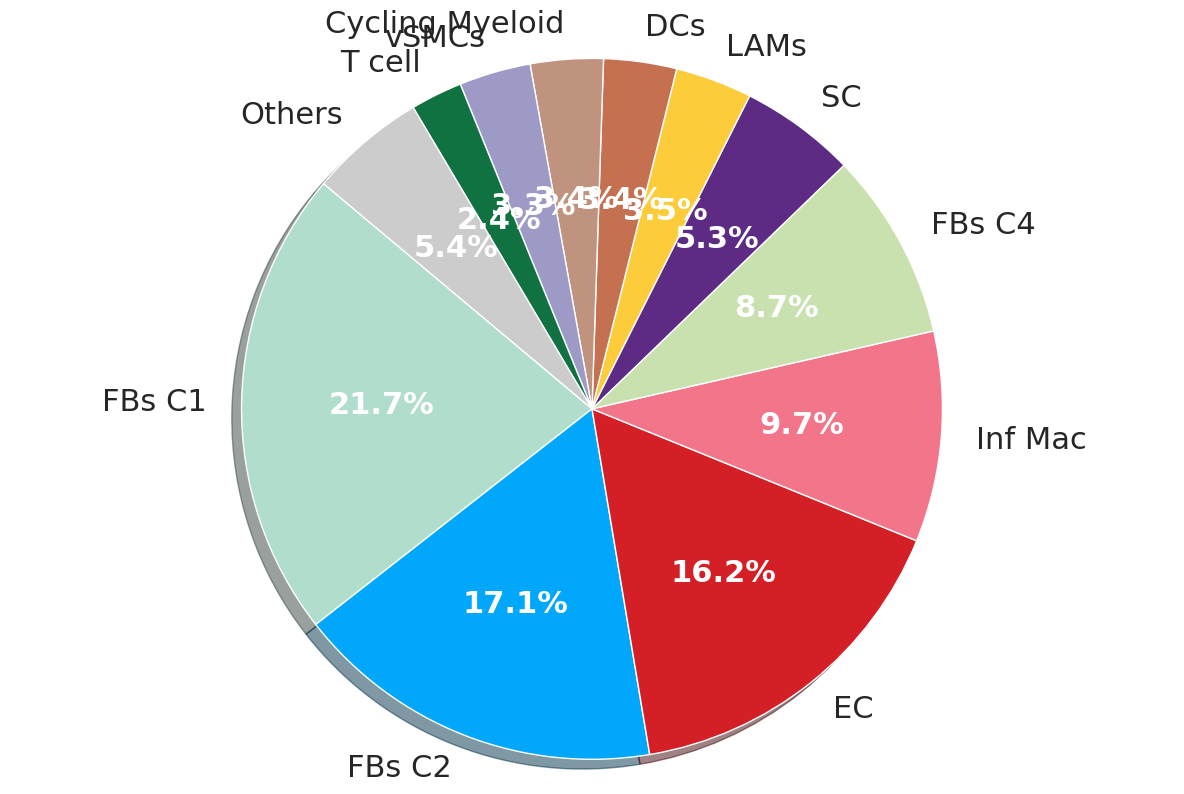

Total number of genes: 18
Number of main genes displayed: 11
Number of merged other genes: 7
Other genes total fraction: 5.36%


In [27]:

# Provided color mapping
color_mapping =   {
   'EC': '#d51f26',
    'T cell': "#0F7240",
    'LAMs': "#FCCC3A",
    'Res Mac': "#d5a339",
    'Inf Mac': '#f3758a',
    'DCs': '#C67052',
    'Mono': '#F49E47',
    'Cycling Myeloid': '#C0937E',
    'SC': '#5d2b84',
    'vSMCs':'#9d9ac6',
    'FBs C1': '#b1ddcc','FBs C2': '#00a7fa','FBs C3': '#92B2D8','FBs C4': '#C9E1AF',
    'FBs C5': '#bbe379','FBs C6': '#b9e6fb','FBs C7': '#7AA15E','FBs C8': '#31aaaa'
}



# Prepare plotting data
labels = gene_percentage_df['gene'].tolist()
sizes = gene_percentage_df['percentage'].tolist()

# Match each gene to its corresponding color
colors = [color_mapping.get(gene, '#cccccc') for gene in labels]  # default gray for unmatched genes

# Set a threshold to merge genes with small proportions
threshold = 2.0  # genes below 2% are merged into "Others"

# Separate main genes from other genes
main_genes = gene_percentage_df[gene_percentage_df['percentage'] >= threshold]
other_genes = gene_percentage_df[gene_percentage_df['percentage'] < threshold]

# Prepare plotting data
main_labels = main_genes['gene'].tolist()
main_sizes = main_genes['percentage'].tolist()
main_colors = [color_mapping.get(gene, '#cccccc') for gene in main_labels]

# If there are small-proportion genes, add an "Others" category
if len(other_genes) > 0:
    other_percentage = other_genes['percentage'].sum()
    main_labels.append(f'Others')
    main_sizes.append(other_percentage)
    main_colors.append('#cccccc')  # gray denotes other genes

# Draw the optimized pie chart
plt.figure(figsize=(12, 8))
wedges, texts, autotexts = plt.pie(
    main_sizes,
    labels=main_labels,
    colors=main_colors,
    autopct='%1.1f%%',
    startangle=140,
    shadow=True,
    textprops={'fontsize': 22}
)

# Beautify
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.axis('equal')
plt.tight_layout()

# Save the figure
plt.savefig('./SC CON _pie_chart.png',########change here
            dpi=500, bbox_inches='tight', facecolor='white')
plt.show()

# Print summary statistics
print(f"Total number of genes: {len(gene_percentage_df)}")
print(f"Number of main genes displayed: {len(main_genes)}")
print(f"Number of merged other genes: {len(other_genes)}")
print(f"Other genes total fraction: {other_genes['percentage'].sum():.2f}%")

In [59]:
#adata.write("./LEC_NMF_CN.h5ad")

In [8]:
# Call the function to compute gene differences between the neighborhoods of two cell types  #functions are at the bottom
results_fdr = compare_neighborhood_expression_corrected(
    adata, 
    group_col='Hip', 
    group_a='niche_2',    #a vs b
    group_b='niche_3',
    correction_method='fdr_bh',  # FDR correction
    pval_threshold=0.01,        # stricter threshold
    min_expr_cells=10           # require expression in at least 10 cells
)


In [9]:

print(f"Number of significant genes after FDR correction: {len(results_fdr['significant_genes'])}")

top_genes = results_fdr['significant_genes'].sort_values('adj_p_value').head(10)
all_gene = results_fdr['significant_genes'].sort_values('adj_p_value')

all_gene.to_csv('./neiborhood diff gene.csv', index=False)
top_genes

Number of significant genes after FDR correction: 8


,gene,niche_2_vs_niche_3_log2FC,abs_log2FC,p_value,adj_p_value,significant,valid_gene,mean_expr_a,mean_expr_b,expr_ratio
6,Neurons_IN,0.005184,0.005184,5.589487e-309,5.589487e-308,True,True,0.020042,0.014858,1.348802
1,EC,0.005239,0.005239,1.489341e-104,7.446703e-104,True,True,0.035595,0.030356,1.172544
5,Neurons_EX,-0.007458,0.007458,9.305453e-45,3.101818e-44,True,True,0.791968,0.799425,0.990670
0,Astro,0.003304,0.003304,1.767661e-39,4.419152e-39,True,True,0.087879,0.084575,1.039048
3,FBs,-0.001108,0.001108,6.855482e-37,1.371096e-36,True,True,0.001601,0.002710,0.590807
2,Epen,-0.003498,0.003498,5.390807e-26,8.984678e-26,True,True,0.000526,0.004024,0.130690
8,Oligo,-0.001756,0.001756,2.453927e-17,3.505610e-17,True,True,0.026631,0.028387,0.938108
4,Micro,-0.000128,0.000128,2.964052e-06,3.705064e-06,True,True,0.018410,0.018538,0.993058


In [52]:
# Compute A 
adata2 = adata####### change here, two places in total

adata2= sm.tl.spatial_count(adata2, phenotype='Cell_Anno', # cells
                            method='radius', radius=50, label='spatial_count',imageid='batch')
adata2 = ad.AnnData(X=adata2.uns['spatial_count'],obs = adata2.obs,uns = adata2.uns)

adata2.var.index = adata2.uns['spatial_count'].columns

adata2.uns['spatial_count'] = adata2.uns['spatial_count'].loc[adata.obs.index,:]


Identifying neighbours within 50 pixels of every cell


In [74]:
adata2.uns['spatial_count'] 

neighbour_phenotype,Astro,EC,Epen,FBs,Micro,Neurons_EX,Neurons_IN,OPC,Oligo,Peri
abaojamg-1_IWD,0.027397,0.041096,0.0,0.0,0.027397,0.863014,0.013699,0.013699,0.013699,0.000000
abapbpgb-1_IWD,0.000000,0.025641,0.0,0.0,0.000000,0.948718,0.025641,0.000000,0.000000,0.000000
abapdpam-1_IWD,0.000000,0.012048,0.0,0.0,0.000000,0.951807,0.024096,0.000000,0.000000,0.012048
abbbdhbo-1_IWD,0.200000,0.000000,0.0,0.0,0.000000,0.800000,0.000000,0.000000,0.000000,0.000000
abbbihlg-1_IWD,0.047619,0.023810,0.0,0.0,0.000000,0.928571,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
oihfipai-1_CWD,0.092784,0.020619,0.0,0.0,0.000000,0.814433,0.020619,0.010309,0.041237,0.000000
oihfmidd-1_CWD,0.075269,0.032258,0.0,0.0,0.032258,0.817204,0.032258,0.000000,0.010753,0.000000
oihfnhjp-1_CWD,0.024691,0.012346,0.0,0.0,0.012346,0.864198,0.086420,0.000000,0.000000,0.000000
oihfomnh-1_CWD,0.000000,0.013889,0.0,0.0,0.013889,0.958333,0.013889,0.000000,0.000000,0.000000


In [53]:
adata1 = adata[adata.obs['niche'].isin(['niche2', 'niche1'])]


Found 5528 FBs C1 cells
Number of FBs C1 cells in group MP: 3107
Number of FBs C1 cells in group CON: 2421


/tmp/ipykernel_1940/3882704364.py:273: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1940/3882704364.py:278: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1940/3882704364.py:282: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1940/3882704364.py:273: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1940/3882704364.py:278: FutureWarning:



Passing `palette` without assigning `hue` is de

✨ Figure saved to: ./_neighborhood.pdf
🎯 Top significant gene: Inf Mac (p=0.000000)


/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 127800 (\N{CHERRY BLOSSOM}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 127872 (\N{RIBBON}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 32454 (\N{CJK UNIFIED IDEOGRAPH-7EC6}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 32990 (\N{CJK UNIFIED IDEOGRAPH-80DE}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 22312 (\N{CJK UNIF

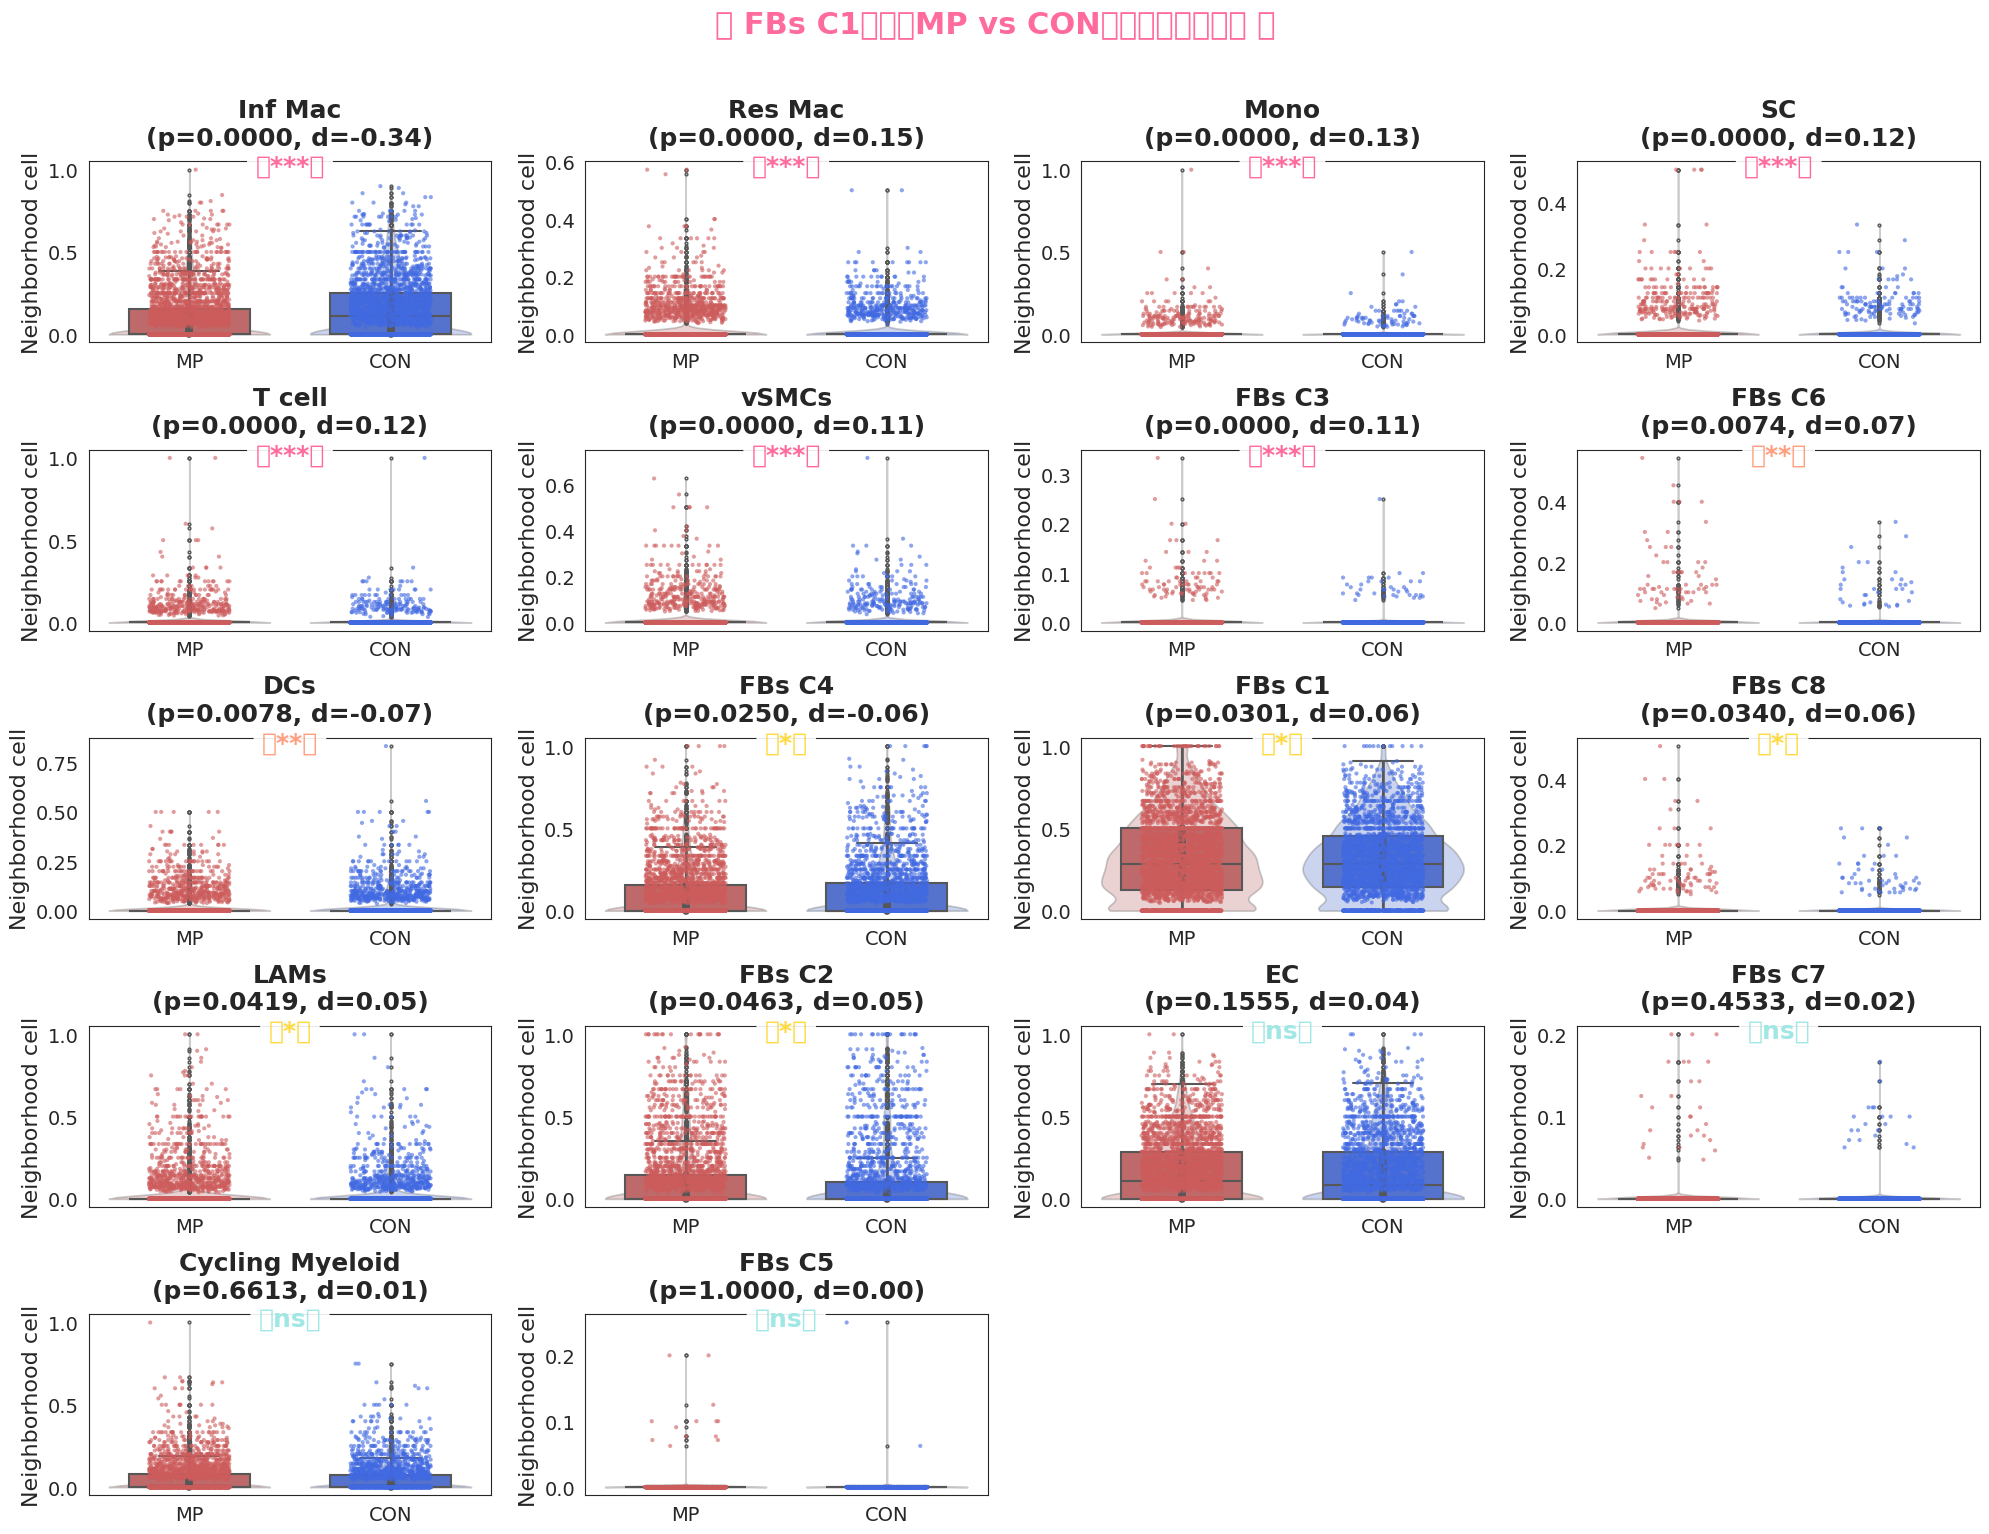

In [54]:
### Compute the difference in the proportion of neighboring cells of a certain cell type between two groups
##functions are at the bottom
results = compare_neighborhood_cell(
    adata1,
    niche_col='Type',
    group_a='MP', 
    group_b='CON',
    target_celltype='FBs C1',
    colors=['#CD5C5C', '#4169E1'],  # custom colors
    top_genes=20,
    font_size=16,  # larger font
    title_size=18,  # larger title
    save_path='./_neighborhood.pdf'
)
# View the most significant genes
top_gene = results['top_statistics'].iloc[0]['gene']
print(f"🎯 Top significant gene: {top_gene} (p={results['top_statistics'].iloc[0]['p_value']:.6f})")

In [39]:
def compare_neighborhood_expression_corrected(adata, group_col, group_a, group_b, 
                                            neighborhood_matrix_key='spatial_count',
                                            min_cells=10, pval_threshold=0.05,
                                            correction_method='fdr_bh', min_expr_cells=5):
    """
    Compare the neighborhood cell composition and gene expression differences between two cell populations (with multiple correction methods)
    """
    
    # 1. Basic checks (as before)
    if group_col not in adata.obs.columns:
        raise ValueError(f"Column '{group_col}' not found in adata.obs")
    
    if neighborhood_matrix_key not in adata.uns:
        raise ValueError(f"Neighborhood matrix '{neighborhood_matrix_key}' not found in adata.uns")
    
    # 2. Prepare the comparison groups
    adata.obs[group_col] = adata.obs[group_col].astype('category')
    group_a_idx = adata.obs[adata.obs[group_col] == group_a].index
    group_b_idx = adata.obs[adata.obs[group_col] == group_b].index
    
    if len(group_a_idx) < min_cells or len(group_b_idx) < min_cells:
        raise ValueError(f"At least one group has fewer than {min_cells} cells")
    
    # 3. Get the neighborhood matrix
    neighborhood_matrix = adata.uns[neighborhood_matrix_key]
    
    # 4. Compare the neighborhood cell composition (as before)
    neighborhood_a = neighborhood_matrix.loc[group_a_idx].mean(axis=0)
    neighborhood_b = neighborhood_matrix.loc[group_b_idx].mean(axis=0)
    neighborhood_diff = neighborhood_a - neighborhood_b
    
    # 5. Differential gene expression analysis (improved version)
    expr_a = adata[group_a_idx, :].X
    expr_b = adata[group_b_idx, :].X
    
    if hasattr(expr_a, 'toarray'):
        expr_a = expr_a.toarray()
        expr_b = expr_b.toarray()
    
    gene_diff = expr_a.mean(axis=0) - expr_b.mean(axis=0)
    
    # 6. Improved statistical testing and correction
    from statsmodels.stats.multitest import multipletests
    
    p_values = []
    valid_genes = []
    
    for i, gene in enumerate(adata.var_names):
        expr_a_gene = expr_a[:, i]
        expr_b_gene = expr_b[:, i]
        
        # Stricter filtering criteria
        n_expr_a = np.sum(expr_a_gene > 0)
        n_expr_b = np.sum(expr_b_gene > 0)
        
        # Require expression in at least min_expr_cells cells
        if n_expr_a < min_expr_cells and n_expr_b < min_expr_cells:
            p_values.append(1.0)
            valid_genes.append(False)
            continue
        
        valid_genes.append(True)
        
        try:
            # Use the Mann-Whitney U test (more robust for single-cell data)
            u_stat, p_val = stats.mannwhitneyu(expr_a_gene, expr_b_gene, alternative='two-sided')
            p_values.append(p_val)
        except:
            p_values.append(1.0)
    
    # Correct only the valid genes
    valid_p_values = [p for i, p in enumerate(p_values) if valid_genes[i]]
    
    if len(valid_p_values) > 0:
        # Multiple testing correction
        if correction_method == 'fdr_bh':
            # Benjamini-Hochberg FDR correction
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='fdr_bh')
        elif correction_method == 'bonferroni':
            # Bonferroni correction (strictest)
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='bonferroni')
        elif correction_method == 'fdr_by':
            # Benjamini-Yekutieli correction
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='fdr_by')
        else:
            raise ValueError("Unsupported correction method")
        
        # Rebuild the complete adj_p array
        full_adj_p = np.ones(len(p_values))
        valid_idx = 0
        for i, is_valid in enumerate(valid_genes):
            if is_valid:
                full_adj_p[i] = adj_p[valid_idx]
                valid_idx += 1
    else:
        full_adj_p = np.ones(len(p_values))
    
    # 7. Create the result DataFrame
    result_df = pd.DataFrame({
        'gene': adata.var_names,
        f'{group_a}_vs_{group_b}_log2FC': gene_diff,
        'abs_log2FC': abs(gene_diff),
        'p_value': p_values,
        'adj_p_value': full_adj_p,
        'significant': full_adj_p < pval_threshold,
        'valid_gene': valid_genes
    })
    
    # 8. Add expression level information
    result_df['mean_expr_a'] = expr_a.mean(axis=0)
    result_df['mean_expr_b'] = expr_b.mean(axis=0)
    result_df['expr_ratio'] = result_df['mean_expr_a'] / (result_df['mean_expr_b'] + 1e-6)
    
    # 9. Visualization (as before, omitted)
    # ... visualization code ...
    
    # 10. Return the results
    results = {
        'group_a': group_a,
        'group_b': group_b,
        'correction_method': correction_method,
        'pval_threshold': pval_threshold,
        'neighborhood_diff': neighborhood_diff,
        'expression_results': result_df,
        'significant_genes': result_df[result_df['significant']],
        'valid_genes_count': sum(valid_genes),
        'significant_count': sum(result_df['significant'])
    }
    
    return results




def compare_neighborhood_cell(adata, niche_col='Hip', group_a='niche_2', group_b='niche_3',
                              cell_anno_col='Cell_Anno', target_celltype='EC',
                              colors=['#FF9AA2', '#B5EAD7'],  # manually set colors
                              top_genes=20, figsize=(20, 15), save_path=None,
                              font_size=14, title_size=16):
    """
    Compare the gene expression differences between two niche groups in EC cells (cute style, customizable colors)
    
    Parameters:
    -----------
    adata : AnnData
        AnnData object containing gene expression data
    niche_col : str, default='Hip'
        niche grouping column name
    group_a, group_b : str, default=('niche_2', 'niche_3')
        Names of the two groups to compare
    cell_anno_col : str, default='Cell_Anno'
        Cell type annotation column name
    target_celltype : str, default='EC'
        Target cell type
    colors : list, default=['#FF9AA2', '#B5EAD7']
        Two group colors, [group_a color, group_b color]
    top_genes : int, default=20
        How many top differential genes to display
    figsize : tuple, default=(20, 15)
        Figure size
    save_path : str, optional
        Save path
    font_size : int, default=14
        Base font size
    title_size : int, default=16
        Title font size
    """
    
    # 1. Set the plotting style (remove grid)
    plt.style.use('default')
    sns.set_style("white")  # remove the grid background
    
    # 2. Filter EC cells
    ec_cells = adata.obs[adata.obs[cell_anno_col] == target_celltype].index
    print(f"Found {len(ec_cells)} {target_celltype} cells")
    
    if len(ec_cells) == 0:
        raise ValueError(f"No {target_celltype} cells found")
    
    # 3. Filter the two groups among EC cells
    group_a_ec = adata.obs[(adata.obs[cell_anno_col] == target_celltype) & 
                          (adata.obs[niche_col] == group_a)].index
    group_b_ec = adata.obs[(adata.obs[cell_anno_col] == target_celltype) & 
                          (adata.obs[niche_col] == group_b)].index
    
    print(f"Number of {target_celltype} cells in group {group_a}: {len(group_a_ec)}")
    print(f"Number of {target_celltype} cells in group {group_b}: {len(group_b_ec)}")
    
    if len(group_a_ec) == 0 or len(group_b_ec) == 0:
        raise ValueError(f"At least one group has 0 {target_celltype} cells")
    
    # 4. Extract the gene expression data
    expr_matrix = adata.X
    if hasattr(expr_matrix, 'toarray'):
        expr_matrix = expr_matrix.toarray()
    
    expr_df = pd.DataFrame(expr_matrix, index=adata.obs.index, columns=adata.var_names)
    
    # 5. Statistical testing
    genes = adata.var_names
    p_values = {}
    mean_diff = {}
    effect_size = {}
    
    for gene in genes:
        expr_a = expr_df.loc[group_a_ec, gene]
        expr_b = expr_df.loc[group_b_ec, gene]
        
        # Filter lowly expressed genes
        if np.sum(expr_a > 0) < 5 or np.sum(expr_b > 0) < 5:
            p_values[gene] = 1.0
            mean_diff[gene] = 0
            effect_size[gene] = 0
            continue
        
        # Compute the test statistic
        mean_a = expr_a.mean()
        mean_b = expr_b.mean()
        mean_diff[gene] = mean_a - mean_b
        
        try:
            t_stat, p_val = stats.ttest_ind(expr_a, expr_b, equal_var=False)
            p_values[gene] = p_val
            
            pooled_std = np.sqrt((expr_a.std()**2 + expr_b.std()**2) / 2)
            if pooled_std > 0:
                effect_size[gene] = (mean_a - mean_b) / pooled_std
            else:
                effect_size[gene] = 0
        except:
            p_val = 1.0
            p_values[gene] = p_val
            effect_size[gene] = 0
    
    # 6. Create the result DataFrame
    result_df = pd.DataFrame({
        'gene': genes,
        f'{group_a}_mean': [expr_df.loc[group_a_ec, gene].mean() for gene in genes],
        f'{group_b}_mean': [expr_df.loc[group_b_ec, gene].mean() for gene in genes],
        'mean_difference': [mean_diff[gene] for gene in genes],
        'p_value': [p_values[gene] for gene in genes],
        'effect_size': [effect_size[gene] for gene in genes]
    })
    
    result_df_sorted = result_df.sort_values('p_value')
    
    # 7. Draw cute-style boxplots
    top_genes_list = result_df_sorted.head(top_genes)['gene'].tolist()
    
    n_cols = 4
    n_rows = (len(top_genes_list) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = axes.flatten() if n_rows > 1 else [axes]
    
    for i, gene in enumerate(top_genes_list):
        if i >= len(axes):
            break
            
        # Extract the data
        expr_a = expr_df.loc[group_a_ec, gene]
        expr_b = expr_df.loc[group_b_ec, gene]
        p_val = p_values[gene]
        effect = effect_size[gene]
        
        # Create the plotting data
        data_to_plot = pd.DataFrame({
            'Group': [group_a] * len(expr_a) + [group_b] * len(expr_b),
            'Expression': np.concatenate([expr_a, expr_b])
        })
        
        # Draw the boxplot (with custom colors)
        sns.boxplot(data=data_to_plot, x='Group', y='Expression', 
                   palette=colors, width=0.6, ax=axes[i], 
                   fliersize=2, linewidth=1.5)
        
        # Add a violin plot
        sns.violinplot(data=data_to_plot, x='Group', y='Expression', 
                      palette=colors, alpha=0.3, ax=axes[i], cut=0)
        
        # Add a scatter plot
        sns.stripplot(data=data_to_plot, x='Group', y='Expression', 
                     palette=colors, alpha=0.6, size=3, jitter=0.2, ax=axes[i])
        
        # Add the statistical annotation
        if p_val < 0.001:
            p_text = '✨***✨'
            text_color = '#FF6B9D'
        elif p_val < 0.01:
            p_text = '✨**✨'
            text_color = '#FF9F7F'
        elif p_val < 0.05:
            p_text = '✨*✨'
            text_color = '#FFD93D'
        else:
            p_text = '🌸ns🌸'
            text_color = '#A0E7E5'
        
        # Add the p-value annotation
        y_max = max(expr_a.max(), expr_b.max())
        axes[i].text(0.5, y_max * 0.95, p_text, ha='center', va='bottom', 
                    fontsize=font_size+2, fontweight='bold', color=text_color,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.9))
        
        # Set the title and labels (larger font)
        axes[i].set_title(f'{gene}\n(p={p_val:.4f}, d={effect:.2f})', 
                         fontsize=title_size, fontweight='bold', pad=12)
        axes[i].set_xlabel('', fontsize=font_size)
        axes[i].set_ylabel('Neighborhood cell', fontsize=font_size)
        
        # Beautify the axes (larger tick labels)
        axes[i].tick_params(axis='both', which='major', labelsize=font_size-2)
        
        # Remove the grid (keep the frame)
        axes[i].grid(False)
        axes[i].spines['top'].set_visible(True)
        axes[i].spines['right'].set_visible(True)
        axes[i].spines['bottom'].set_visible(True)
        axes[i].spines['left'].set_visible(True)
    
    # Hide the extra subplots
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    # Set the overall title
    plt.suptitle(f'🎀 Gene expression differences of {target_celltype} cells between {group_a} vs {group_b} 🎀', 
                fontsize=title_size+4, fontweight='bold', y=1.02, color='#FF6B9D')
    plt.tight_layout()
    
    # 8. Save the figure
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300, facecolor='white')
        print(f"✨ Figure saved to: {save_path}")
    
    # 9. Return the results
    results = {
        'figure': fig,
        'all_statistics': result_df,
        'top_statistics': result_df_sorted.head(top_genes),
        'p_values': p_values,
        'mean_diff': mean_diff,
        'effect_sizes': effect_size
    }
    
    return results